In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv('3_4_2026/log/PPO_log_hover_projectairsim.csv')
#lay 100000 step dau tien
data = data[data['timestep'] <= 100000]

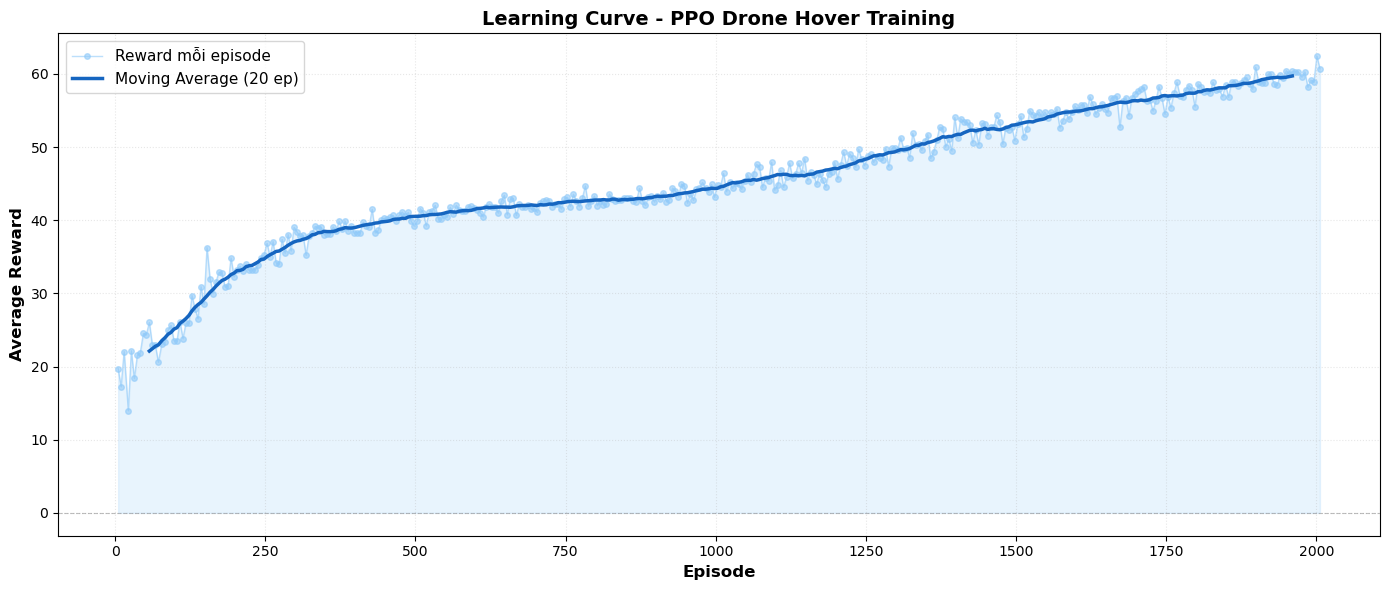

✅ Số episodes: 2006
   Tổng timesteps: 100,000


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# === Biểu đồ 1: Learning Curve (Reward mỗi episode) ===
fig, ax = plt.subplots(figsize=(14, 6))

# Vẽ reward thô
ax.plot(data['episode'], data['avg_reward'], 'o-', color='#90CAF9', 
        linewidth=1, markersize=4, alpha=0.6, label='Reward mỗi episode')

# Vẽ đường trung bình động (Moving Average)
window = 20
data['ma_reward'] = data['avg_reward'].rolling(window=window, center=True).mean()
ax.plot(data['episode'], data['ma_reward'], color='#1565C0', 
        linewidth=2.5, label=f'Moving Average ({window} ep)')

# Trang trí
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax.fill_between(data['episode'], data['avg_reward'], alpha=0.2, color='#90CAF9')
ax.set_xlabel('Episode', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Reward', fontsize=12, fontweight='bold')
ax.set_title('Learning Curve - PPO Drone Hover Training', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"✅ Số episodes: {int(data['episode'].max())}")
print(f"   Tổng timesteps: {data['timestep'].max():,.0f}")


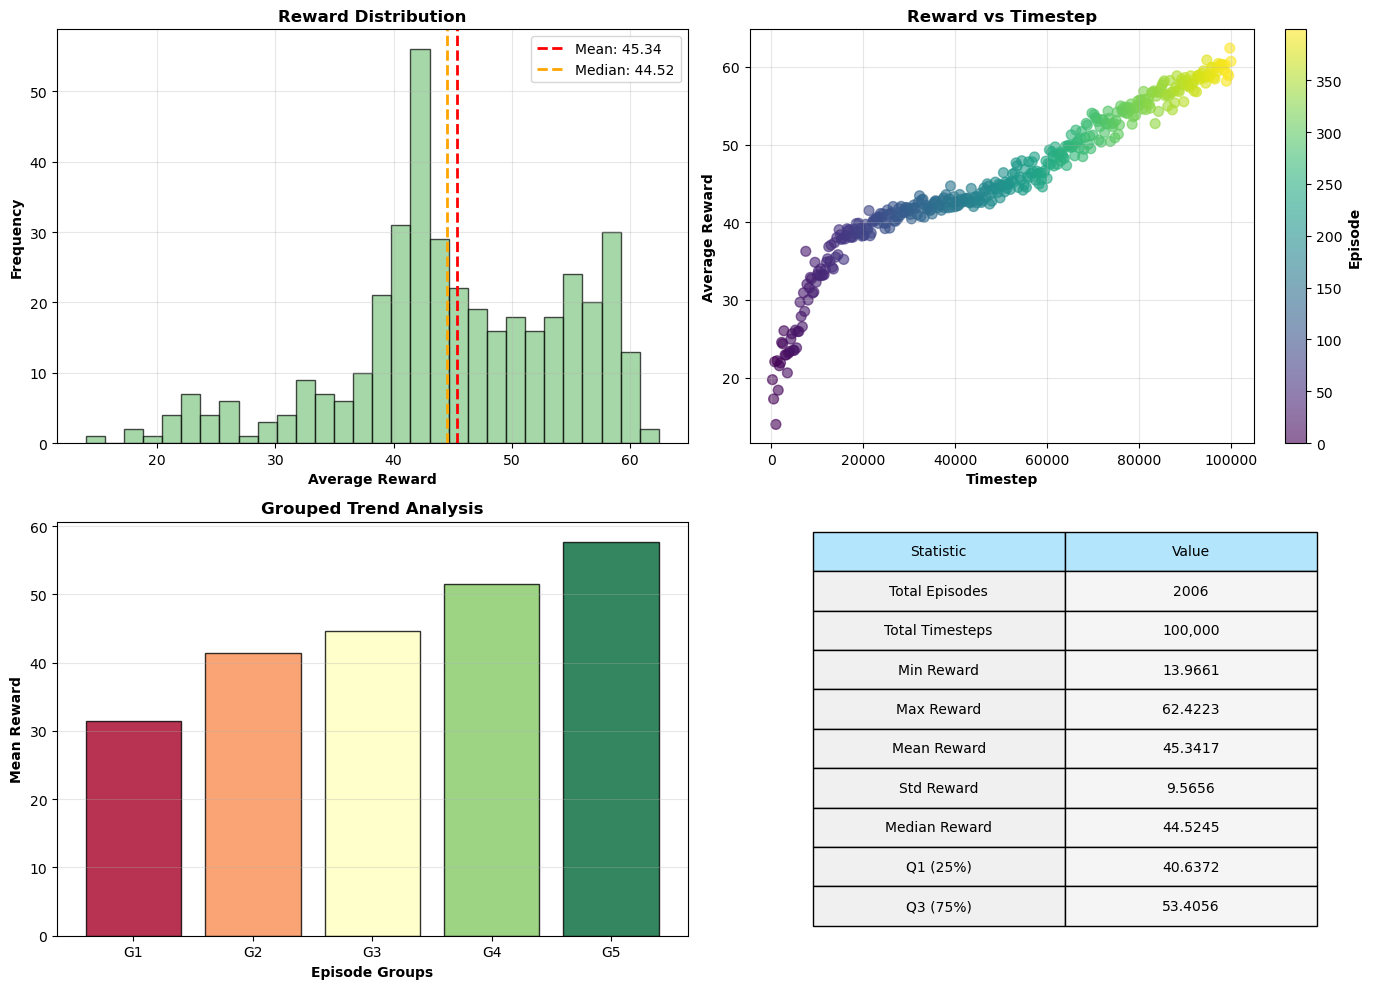

In [6]:
# === Figure 2: Statistics & Analysis ===
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 2a. Reward Distribution Histogram
ax = axes[0, 0]
ax.hist(data['avg_reward'], bins=30, color='#81C784', edgecolor='black', alpha=0.7)
ax.axvline(data['avg_reward'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {data['avg_reward'].mean():.2f}")
ax.axvline(data['avg_reward'].median(), color='orange', linestyle='--', linewidth=2, label=f"Median: {data['avg_reward'].median():.2f}")
ax.set_xlabel('Average Reward', fontweight='bold')
ax.set_ylabel('Frequency', fontweight='bold')
ax.set_title('Reward Distribution', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 2b. Reward vs Timestep
ax = axes[0, 1]
ax.scatter(data['timestep'], data['avg_reward'], c=data.index, cmap='viridis', s=50, alpha=0.6)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label('Episode', fontweight='bold')
ax.set_xlabel('Timestep', fontweight='bold')
ax.set_ylabel('Average Reward', fontweight='bold')
ax.set_title('Reward vs Timestep', fontweight='bold')
ax.grid(True, alpha=0.3)

# 2c. Trend Analysis
ax = axes[1, 0]
n_groups = 5
n_rows = len(data)  # Number of data rows
group_size = n_rows // n_groups
groups = []
for i in range(n_groups):
    start = i * group_size
    end = (i + 1) * group_size if i < n_groups - 1 else n_rows
    groups.append(data['avg_reward'].iloc[start:end].mean())

group_labels = [f"G{i+1}" for i in range(n_groups)]
colors_bar = plt.cm.RdYlGn(np.linspace(0, 1, n_groups))
ax.bar(group_labels, groups, color=colors_bar, edgecolor='black', alpha=0.8)
ax.set_xlabel('Episode Groups', fontweight='bold')
ax.set_ylabel('Mean Reward', fontweight='bold')
ax.set_title('Grouped Trend Analysis', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# 2d. Statistical Summary Table
ax = axes[1, 1]
ax.axis('off')
stats = {
    'Total Episodes': int(data['episode'].max()),
    'Total Timesteps': f"{data['timestep'].max():,.0f}",
    'Min Reward': f"{data['avg_reward'].min():.4f}",
    'Max Reward': f"{data['avg_reward'].max():.4f}",
    'Mean Reward': f"{data['avg_reward'].mean():.4f}",
    'Std Reward': f"{data['avg_reward'].std():.4f}",
    'Median Reward': f"{data['avg_reward'].median():.4f}",
    'Q1 (25%)': f"{data['avg_reward'].quantile(0.25):.4f}",
    'Q3 (75%)': f"{data['avg_reward'].quantile(0.75):.4f}",
}

table_data = [[k, v] for k, v in stats.items()]
table = ax.table(cellText=table_data, colLabels=['Statistic', 'Value'], 
                cellLoc='center', loc='center', colWidths=[0.4, 0.4])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Styling the table header and cells
for i in range(len(stats) + 1):
    table[(i, 0)].set_facecolor('#B3E5FC' if i == 0 else '#F0F0F0')
    table[(i, 1)].set_facecolor('#B3E5FC' if i == 0 else '#F5F5F5')

plt.tight_layout()
plt.show()

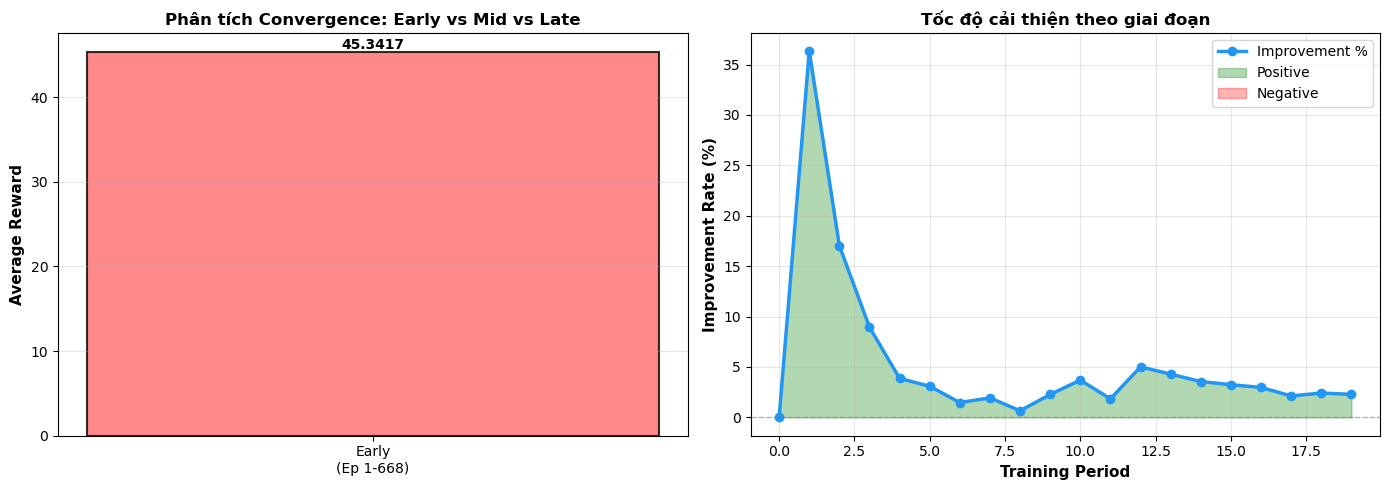


📊 TÓM TẮT KẾT QUẢ HUẤN LUYỆN
✓ Giai đoạn Early:  Reward trung bình = 45.3417
✓ Giai đoạn Mid:    Reward trung bình = nan
✓ Giai đoạn Late:   Reward trung bình = nan
  → Cải thiện Early→Late: nan%


In [7]:
# === Biểu đồ 3: Phân tích hội tụ (Convergence) ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3a. Phân chia Early vs Mid vs Late Training
ax = axes[0]
total_episodes = int(data['episode'].max())
third = total_episodes // 3
early = data['avg_reward'].iloc[:third].mean()
mid = data['avg_reward'].iloc[third:2*third].mean()
late = data['avg_reward'].iloc[2*third:].mean()

phases = ['Early\n(Ep 1-%.0f)' % third, 'Mid\n(Ep %.0f-%.0f)' % (third+1, 2*third), 'Late\n(Ep %.0f-%.0f)' % (2*third+1, total_episodes)]
rewards = [early, mid, late]
colors_phase = ['#FF6B6B', '#FFA500', '#4CAF50']

bars = ax.bar(phases, rewards, color=colors_phase, edgecolor='black', linewidth=1.5, alpha=0.8)
ax.set_ylabel('Average Reward', fontweight='bold', fontsize=11)
ax.set_title('Phân tích Convergence: Early vs Mid vs Late', fontweight='bold', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# Thêm giá trị trên cột
for bar, val in zip(bars, rewards):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# 3b. Improvement Rate (% cải thiện)
ax = axes[1]
n_points = 20
step = len(data) // n_points
periods = []
improvements = [0]  # Điểm đầu không có cải thiện

for i in range(1, n_points):
    idx = i * step
    if idx < len(data):
        prev_reward = data['avg_reward'].iloc[max(0, idx - step):(idx)].mean()
        curr_reward = data['avg_reward'].iloc[idx:min(len(data), idx + step)].mean()
        improvement = ((curr_reward - prev_reward) / (abs(prev_reward) + 1e-6)) * 100
        improvements.append(improvement)
        periods.append(i)

periods = [0] + periods
ax.plot(periods, improvements, 'o-', color='#2196F3', linewidth=2.5, markersize=6, label='Improvement %')
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax.fill_between(periods, improvements, where=np.array(improvements)>=0, alpha=0.3, color='green', label='Positive')
ax.fill_between(periods, improvements, where=np.array(improvements)<0, alpha=0.3, color='red', label='Negative')
ax.set_xlabel('Training Period', fontweight='bold', fontsize=11)
ax.set_ylabel('Improvement Rate (%)', fontweight='bold', fontsize=11)
ax.set_title('Tốc độ cải thiện theo giai đoạn', fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# In tóm tắt
print("\n" + "="*60)
print("📊 TÓM TẮT KẾT QUẢ HUẤN LUYỆN")
print("="*60)
print(f"✓ Giai đoạn Early:  Reward trung bình = {early:.4f}")
print(f"✓ Giai đoạn Mid:    Reward trung bình = {mid:.4f}")
print(f"✓ Giai đoạn Late:   Reward trung bình = {late:.4f}")
print(f"  → Cải thiện Early→Late: {((late - early) / (abs(early) + 1e-6) * 100):.1f}%")
print("="*60)

In [8]:
# === Hiển thị dữ liệu & Export ===
print("📋 DỮ LIỆU HUẤN LUYỆN (10 hàng đầu):")
print(data.head(10))
print("\n📋 DỮ LIỆU HUẤN LUYỆN (10 hàng cuối):")
print(data.tail(10))

# Lưu các biểu đồ
# fig1.savefig('learning_curve.png', dpi=150, bbox_inches='tight')
# fig2.savefig('statistics.png', dpi=150, bbox_inches='tight')
# fig3.savefig('convergence.png', dpi=150, bbox_inches='tight')

print("\n✅ Phân tích hoàn tất! Các biểu đồ đã được vẽ.")

📋 DỮ LIỆU HUẤN LUYỆN (10 hàng đầu):
   episode  timestep  avg_reward  ma_reward
0        5       250     19.7267        NaN
1       10       500     17.2412        NaN
2       15       750     22.0392        NaN
3       22      1000     13.9661        NaN
4       27      1250     22.1643        NaN
5       32      1500     18.3726        NaN
6       37      1750     21.5178        NaN
7       42      2000     21.8992        NaN
8       47      2250     24.5348        NaN
9       52      2500     24.3501        NaN

📋 DỮ LIỆU HUẤN LUYỆN (10 hàng cuối):
     episode  timestep  avg_reward  ma_reward
390     1960     97750     60.3416  59.716145
391     1965     98000     60.2938        NaN
392     1970     98250     60.2730        NaN
393     1976     98500     59.5688        NaN
394     1981     98750     60.2749        NaN
395     1986     99000     58.1660        NaN
396     1991     99250     59.1649        NaN
397     1996     99500     58.8775        NaN
398     2001     99750     6